In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
data = pd.read_csv('../data/city_day.csv')
data.head()

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [4]:
data.shape

(29531, 16)

In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  str    
 1   Date        29531 non-null  str    
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 non-null  str    
dtypes: float64(13), str(3)
memory usage: 3.6 MB


In [6]:
data.isnull().sum()

City              0
Date              0
PM2.5          4598
PM10          11140
NO             3582
NO2            3585
NOx            4185
NH3           10328
CO             2059
SO2            3854
O3             4022
Benzene        5623
Toluene        8041
Xylene        18109
AQI            4681
AQI_Bucket     4681
dtype: int64

In [7]:
(data.isnull().mean() * 100).round(2).sort_values(ascending=False)

Xylene        61.32
PM10          37.72
NH3           34.97
Toluene       27.23
Benzene       19.04
AQI           15.85
AQI_Bucket    15.85
PM2.5         15.57
NOx           14.17
O3            13.62
SO2           13.05
NO2           12.14
NO            12.13
CO             6.97
City           0.00
Date           0.00
dtype: float64

In [8]:
data.duplicated().sum()

np.int64(0)

In [9]:
data.describe()

,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI
count,24933.000000,18391.000000,25949.000000,25946.000000,25346.000000,19203.000000,27472.000000,25677.000000,25509.000000,23908.000000,21490.000000,11422.000000,24850.000000
mean,67.450578,118.127103,17.574730,28.560659,32.309123,23.483476,2.248598,14.531977,34.491430,3.280840,8.700972,3.070128,166.463581
std,64.661449,90.605110,22.785846,24.474746,31.646011,25.684275,6.962884,18.133775,21.694928,15.811136,19.969164,6.323247,140.696585
min,0.040000,0.010000,0.020000,0.010000,0.000000,0.010000,0.000000,0.010000,0.010000,0.000000,0.000000,0.000000,13.000000
25%,28.820000,56.255000,5.630000,11.750000,12.820000,8.580000,0.510000,5.670000,18.860000,0.120000,0.600000,0.140000,81.000000
50%,48.570000,95.680000,9.890000,21.690000,23.520000,15.850000,0.890000,9.160000,30.840000,1.070000,2.970000,0.980000,118.000000
75%,80.590000,149.745000,19.950000,37.620000,40.127500,30.020000,1.450000,15.220000,45.570000,3.080000,9.150000,3.350000,208.000000
max,949.990000,1000.000000,390.680000,362.210000,467.630000,352.890000,175.810000,193.860000,257.730000,455.030000,454.850000,170.370000,2049.000000


In [10]:
data['City'].value_counts()

City
Ahmedabad             2009
Bengaluru             2009
Chennai               2009
Delhi                 2009
Lucknow               2009
Mumbai                2009
Hyderabad             2006
Patna                 1858
Gurugram              1679
Visakhapatnam         1462
Amritsar              1221
Jorapokhar            1169
Jaipur                1114
Thiruvananthapuram    1112
Amaravati              951
Brajrajnagar           938
Talcher                925
Kolkata                814
Guwahati               502
Coimbatore             386
Shillong               310
Chandigarh             304
Bhopal                 289
Ernakulam              162
Kochi                  162
Aizawl                 113
Name: count, dtype: int64

### Missing Value & Date Feature Treatment Explanations
1. **Dropping rows with missing `AQI` (15.85%):** `AQI` is the target variable. Imputing missing target values would create synthetic labels and distort model evaluation.
2. **Extracting date-based features (`Year`, `Month`, `DayOfWeek`):** Splitting `Date` captures multi-year pollution trends, winter vs. monsoon seasonal cycles, and weekday vs. weekend traffic variations.
3. **Selecting core pollutants (`PM2.5`, `PM10`, `NO2`, `SO2`, `CO`, `O3`):** Removes sparsely recorded columns like `Xylene` (61.32% missing), `NH3` (34.97%), `Toluene` (27.23%), and `Benzene` (19.04%) that add noise.
4. **City-wise median imputation with global median fallback:** Pollutant readings are right-skewed with extreme winter spikes, making the median more robust than the mean. Imputing within each `City` first preserves local pollution baselines before falling back to the global median.

In [11]:
data = data.dropna(subset=['AQI'])
data.shape

(24850, 16)

In [12]:
data['Date'] = pd.to_datetime(data['Date'])
data['Year'] = data['Date'].dt.year
data['Month'] = data['Date'].dt.month
data['DayOfWeek'] = data['Date'].dt.dayofweek
data[['Date', 'Year', 'Month', 'DayOfWeek']].head()

,Date,Year,Month,DayOfWeek
28,2015-01-29,2015,1,3
29,2015-01-30,2015,1,4
30,2015-01-31,2015,1,5
31,2015-02-01,2015,2,6
32,2015-02-02,2015,2,0


In [13]:
pollutants = ['PM2.5', 'PM10', 'NO2', 'SO2', 'CO', 'O3']
data = data[['City', 'Year', 'Month', 'DayOfWeek'] + pollutants + ['AQI']]
data.head()

,City,Year,Month,DayOfWeek,PM2.5,PM10,NO2,SO2,CO,O3,AQI
28,Ahmedabad,2015,1,3,83.13,NaN,28.71,49.52,6.93,59.76,209.0
29,Ahmedabad,2015,1,4,79.84,NaN,28.68,48.49,13.85,97.07,328.0
30,Ahmedabad,2015,1,5,94.52,NaN,32.66,67.39,24.39,111.33,514.0
31,Ahmedabad,2015,2,6,135.99,NaN,42.08,75.23,43.48,102.70,782.0
32,Ahmedabad,2015,2,0,178.33,NaN,35.31,55.04,54.56,107.38,914.0


In [14]:
for col in pollutants:
    data[col] = data.groupby('City')[col].transform(lambda s: s.fillna(s.median()))
    data[col] = data[col].fillna(data[col].median())

In [15]:
data.isnull().sum()

City         0
Year         0
Month        0
DayOfWeek    0
PM2.5        0
PM10         0
NO2          0
SO2          0
CO           0
O3           0
AQI          0
dtype: int64

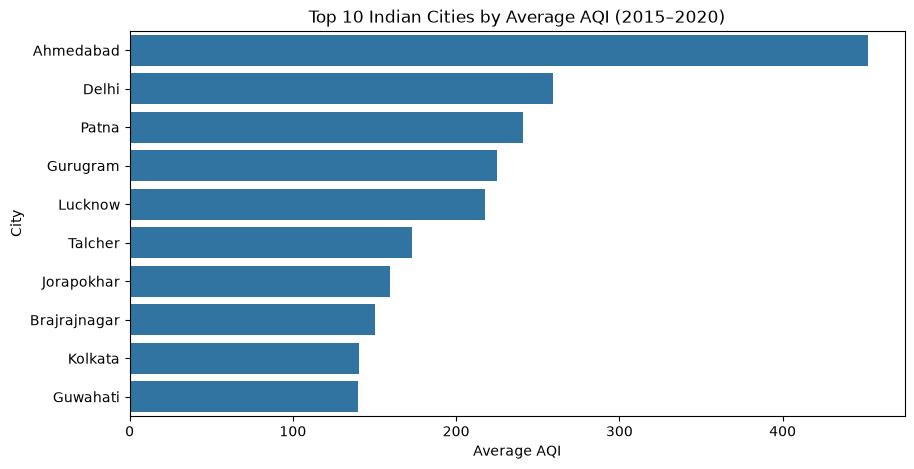

In [16]:
top_cities = data.groupby('City')['AQI'].mean().sort_values(ascending=False).head(10)
plt.figure(figsize=(10, 5))
sns.barplot(x=top_cities.values, y=top_cities.index)
plt.title('Top 10 Indian Cities by Average AQI (2015–2020)')
plt.xlabel('Average AQI')
plt.ylabel('City')
plt.show()

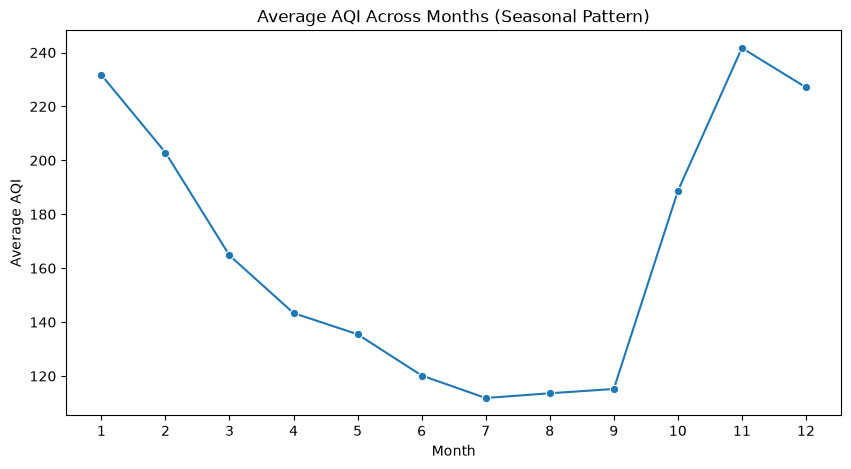

In [17]:
monthly_aqi = data.groupby('Month')['AQI'].mean()
plt.figure(figsize=(10, 5))
sns.lineplot(x=monthly_aqi.index, y=monthly_aqi.values, marker='o')
plt.xticks(range(1, 13))
plt.title('Average AQI Across Months (Seasonal Pattern)')
plt.xlabel('Month')
plt.ylabel('Average AQI')
plt.show()

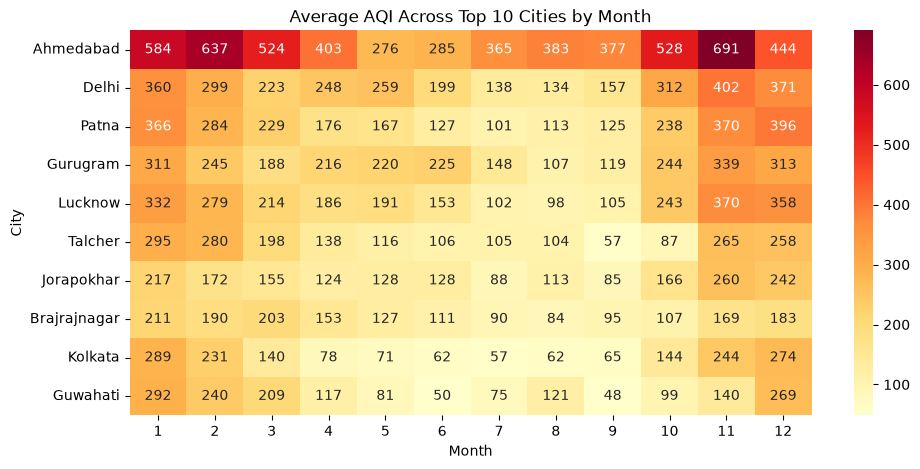

In [18]:
city_month = data[data['City'].isin(top_cities.index)].pivot_table(index='City', columns='Month', values='AQI', aggfunc='mean').loc[top_cities.index]
plt.figure(figsize=(11, 5))
sns.heatmap(city_month, annot=True, fmt='.0f', cmap='YlOrRd')
plt.title('Average AQI Across Top 10 Cities by Month')
plt.xlabel('Month')
plt.ylabel('City')
plt.show()

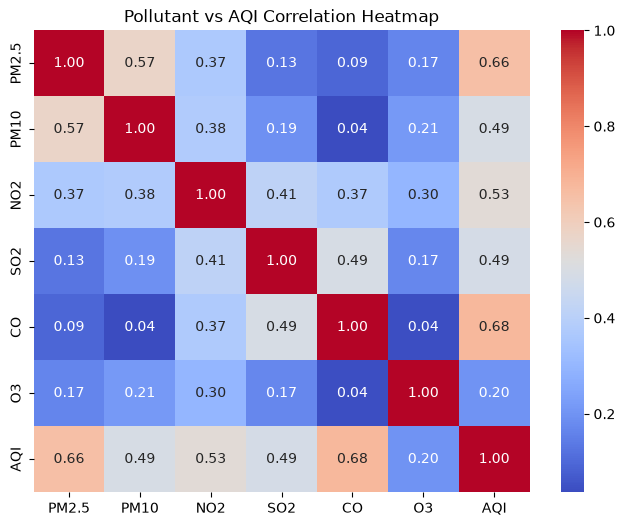

In [19]:
plt.figure(figsize=(8, 6))
sns.heatmap(data[pollutants + ['AQI']].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Pollutant vs AQI Correlation Heatmap')
plt.show()

### Encoding City Feature & Train-Test Split
One-Hot Encoding (`pd.get_dummies`) converts `City` into binary columns without introducing artificial ordinal rankings.

In [20]:
cities_list = sorted(data['City'].unique().tolist())
pollutant_medians = data[pollutants].median().to_dict()

In [21]:
data = pd.get_dummies(data, columns=['City'], drop_first=True, dtype=int)
data.head()

,Year,Month,DayOfWeek,PM2.5,PM10,NO2,SO2,CO,O3,AQI,...,City_Jorapokhar,City_Kochi,City_Kolkata,City_Lucknow,City_Mumbai,City_Patna,City_Shillong,City_Talcher,City_Thiruvananthapuram,City_Visakhapatnam
28,2015,1,3,83.13,107.67,28.71,49.52,6.93,59.76,209.0,...,0,0,0,0,0,0,0,0,0,0
29,2015,1,4,79.84,107.67,28.68,48.49,13.85,97.07,328.0,...,0,0,0,0,0,0,0,0,0,0
30,2015,1,5,94.52,107.67,32.66,67.39,24.39,111.33,514.0,...,0,0,0,0,0,0,0,0,0,0
31,2015,2,6,135.99,107.67,42.08,75.23,43.48,102.70,782.0,...,0,0,0,0,0,0,0,0,0,0
32,2015,2,0,178.33,107.67,35.31,55.04,54.56,107.38,914.0,...,0,0,0,0,0,0,0,0,0,0


In [22]:
X = data.drop(columns=['AQI'])
y = data['AQI']

In [23]:
X.head()

,Year,Month,DayOfWeek,PM2.5,PM10,NO2,SO2,CO,O3,City_Aizawl,...,City_Jorapokhar,City_Kochi,City_Kolkata,City_Lucknow,City_Mumbai,City_Patna,City_Shillong,City_Talcher,City_Thiruvananthapuram,City_Visakhapatnam
28,2015,1,3,83.13,107.67,28.71,49.52,6.93,59.76,0,...,0,0,0,0,0,0,0,0,0,0
29,2015,1,4,79.84,107.67,28.68,48.49,13.85,97.07,0,...,0,0,0,0,0,0,0,0,0,0
30,2015,1,5,94.52,107.67,32.66,67.39,24.39,111.33,0,...,0,0,0,0,0,0,0,0,0,0
31,2015,2,6,135.99,107.67,42.08,75.23,43.48,102.70,0,...,0,0,0,0,0,0,0,0,0,0
32,2015,2,0,178.33,107.67,35.31,55.04,54.56,107.38,0,...,0,0,0,0,0,0,0,0,0,0


In [24]:
from sklearn.model_selection import train_test_split

In [25]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [26]:
X_train.shape, X_test.shape

((19880, 34), (4970, 34))

In [27]:
from sklearn.linear_model import LinearRegression

In [28]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [29]:
lr = LinearRegression()
lr.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](34,)","[ -1.29, -0.37, 0.38,...,-39.22,-50.84,-56.11]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](34,)","['Year','Month','DayOfWeek',...,'City_Talcher','City_Thiruvananthapuram', 'City_Visakhapatnam']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2654
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,34
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,34


In [30]:
lr_pred = lr.predict(X_test)

In [31]:
lr_mae = mean_absolute_error(y_test, lr_pred)
lr_mae

30.14281576228262

In [32]:
lr_mse = mean_squared_error(y_test, lr_pred)
lr_mse

3264.18090767525

In [33]:
lr_rmse = np.sqrt(lr_mse)
lr_rmse

np.float64(57.1330106652472)

In [34]:
lr_r2 = r2_score(y_test, lr_pred)
lr_r2

0.8217368174675121

In [35]:
from sklearn.ensemble import RandomForestRegressor

In [36]:
rf = RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [37]:
rf_pred = rf.predict(X_test)

In [38]:
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_mae

21.14206624969575

In [39]:
rf_mse = mean_squared_error(y_test, rf_pred)
rf_mse

1691.8567198977842

In [40]:
rf_rmse = np.sqrt(rf_mse)
rf_rmse

np.float64(41.132185936293055)

In [41]:
rf_r2 = r2_score(y_test, rf_pred)
rf_r2

0.9076044582673723

In [42]:
models = ['Linear Regression', 'Random Forest']

In [43]:
maes = [lr_mae, rf_mae]

In [44]:
mses = [lr_mse, rf_mse]

In [45]:
rmses = [lr_rmse, rf_rmse]

In [46]:
r2_scores = [lr_r2, rf_r2]

In [47]:
results = pd.DataFrame({'Model': models, 'MAE': maes, 'MSE': mses, 'RMSE': rmses, 'R2 Score': r2_scores})
results

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,30.142816,3264.180908,57.133011,0.821737
1,Random Forest,21.142066,1691.856720,41.132186,0.907604


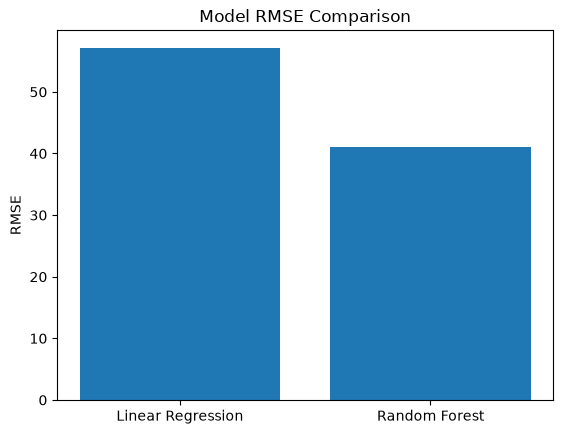

In [48]:
plt.bar(models, rmses)
plt.title('Model RMSE Comparison')
plt.ylabel('RMSE')
plt.show()

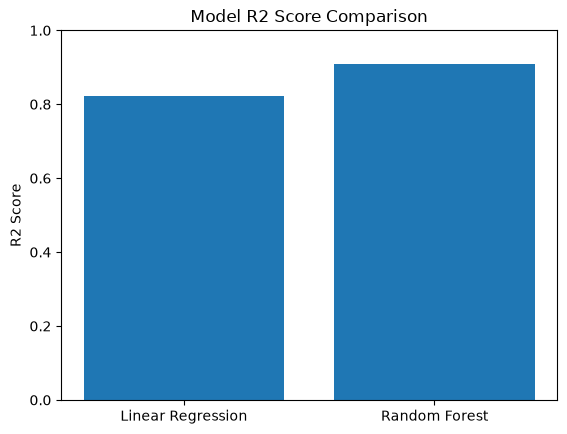

In [49]:
plt.bar(models, r2_scores)
plt.title('Model R2 Score Comparison')
plt.ylabel('R2 Score')
plt.ylim(0, 1.0)
plt.show()

In [50]:
import os, joblib
os.makedirs('../models', exist_ok=True)
joblib.dump(rf, '../models/best_aqi_model.joblib', compress=3)
joblib.dump({'cities': cities_list, 'medians': pollutant_medians, 'feature_columns': X.columns.tolist(), 'metrics': results.to_dict(orient='records')}, '../models/metadata.joblib')

['../models/metadata.joblib']